# Classical Forecasting of Daily Store Sales

## Objectives and Evaluation Protocol

We forecast each store's daily recorded sales amount for a 28-day horizon.
We compare simple baselines, moving-average forecasts, exponential smoothing,
and autoregressive models.

We evaluate all candidates on the same four expanding-window folds.
At each origin, we generate the complete 28-day forecast without updating
the model using validation observations.

We fit preprocessing and model parameters using training data only.
The final holdout, 2024-08-30 through 2024-09-26, remains unopened.

For smoothing models, we inspect the components appropriate to each method:
level for single smoothing; level and trend for double smoothing;
level, trend, and seasonality for triple smoothing.

We select models using cross-validation and discuss their errors, stability,
and limitations. Numerical results and conclusions are added after execution.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42

COLORS = {
    "purple": "#8055B8",
    "pink": "#DB74A5",
    "lavender": "#B59AD8",
    "rose": "#EDADC8",
    "dark": "#453354",
}

sns.set_theme(
    style="whitegrid",
    palette=list(COLORS.values()),
    rc={
        "figure.figsize": (12, 5),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "grid.alpha": 0.25,
    },
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
working_dir = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path
        for path in [working_dir, *working_dir.parents]
        if (
            path / "data" / "processed"
            / "retail_forecasting_config.json"
        ).is_file()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Run the EDA export cell first, then start Jupyter "
        "inside the project directory."
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results" / "classical_forecasting"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

with (
    PROCESSED_DIR / "retail_forecasting_config.json"
).open(encoding="utf-8") as file:
    config = json.load(file)

daily = pd.read_csv(
    PROCESSED_DIR / "retail_daily_store_dev.csv",
    parse_dates=["date"],
    dtype={"store_id": "int64", "y": "float64"},
)

cv_schedule = pd.read_csv(
    PROCESSED_DIR / "retail_cv_schedule.csv",
    parse_dates=["train_end", "validation_start", "validation_end"],
)

HORIZON = int(config["forecast_horizon_days"])
TEST_START = pd.Timestamp(config["test_start"])
SEASON_LENGTH = 7

daily = daily.sort_values(["store_id", "date"]).reset_index(drop=True)

assert not daily.duplicated(["store_id", "date"]).any()
assert daily["date"].max() < TEST_START
assert set(daily["store_id"]) == set(config["store_ids"])
assert HORIZON == 28

store_series = {
    int(store_id): (
        group.set_index("date")["y"].sort_index().asfreq("D")
    )
    for store_id, group in daily.groupby("store_id")
}

display(cv_schedule)

,fold,train_end,validation_start,validation_end,horizon_days
0,1,2024-05-09,2024-05-10,2024-06-06,28
1,2,2024-06-06,2024-06-07,2024-07-04,28
2,3,2024-07-04,2024-07-05,2024-08-01,28
3,4,2024-08-01,2024-08-02,2024-08-29,28


## 1. Training and Validation Integrity

We preserve the calendar index and do not remove missing dates.

For models requiring complete training data, we fill a missing training
observation using the median of up to eight preceding observations from
the same weekday. If none are available, we use the most recent preceding
observed value.

This fixed rule uses only earlier observed values. We do not impute
validation targets. We require complete validation windows and report
training lengths and imputation counts for every store and fold.

In [3]:
def prepare_training_series(raw_train):
    """Fill gaps using earlier observed values only."""
    train = raw_train.astype(float).copy()

    if train.empty:
        raise ValueError("Empty training series.")

    observed = train.dropna()

    if not np.isfinite(observed.to_numpy()).all():
        raise ValueError("Non-finite training observations.")

    imputed_count = 0

    for date in train.index[train.isna()]:
        past = observed.loc[observed.index < date]

        same_weekday = past.loc[
            past.index.dayofweek == date.dayofweek
        ].tail(8)

        if not same_weekday.empty:
            replacement = same_weekday.median()
        elif not past.empty:
            replacement = past.iloc[-1]
        else:
            raise ValueError(f"No earlier observations for {date}.")

        train.loc[date] = replacement
        imputed_count += 1

    return train, imputed_count


fold_data = {}
audit_rows = []

for fold in cv_schedule.itertuples(index=False):
    validation_dates = pd.date_range(
        fold.validation_start,
        fold.validation_end,
        freq="D",
    )

    assert len(validation_dates) == HORIZON
    assert fold.validation_start == (
        fold.train_end + pd.Timedelta(days=1)
    )
    assert fold.validation_end < TEST_START

    for store_id, series in store_series.items():
        raw_train = series.loc[:fold.train_end]
        valid = series.reindex(validation_dates)

        if valid.isna().any():
            raise ValueError(
                f"Missing validation targets: "
                f"store {store_id}, fold {fold.fold}"
            )

        if not np.isfinite(valid.to_numpy()).all():
            raise ValueError("Non-finite validation targets.")

        train, imputed_count = prepare_training_series(raw_train)

        assert train.index.max() < valid.index.min()
        assert len(train) >= 2 * SEASON_LENGTH

        fold_data[(int(fold.fold), store_id)] = {
            "train": train,
            "valid": valid,
        }

        audit_rows.append({
            "fold": int(fold.fold),
            "store_id": store_id,
            "train_start": train.index.min(),
            "train_end": train.index.max(),
            "train_days": len(train),
            "imputed_training_days": imputed_count,
            "validation_start": valid.index.min(),
            "validation_end": valid.index.max(),
            "validation_days": len(valid),
        })

fold_audit = pd.DataFrame(audit_rows)
display(fold_audit)

assert len(fold_data) == 4 * len(store_series)
print("All store–fold combinations passed the integrity checks.")

,fold,store_id,train_start,train_end,train_days,imputed_training_days,validation_start,validation_end,validation_days
0,1,1,2022-08-28,2024-05-09,621,0,2024-05-10,2024-06-06,28
1,1,2,2022-08-28,2024-05-09,621,0,2024-05-10,2024-06-06,28
2,1,3,2022-08-28,2024-05-09,621,1,2024-05-10,2024-06-06,28
3,1,4,2023-12-13,2024-05-09,149,0,2024-05-10,2024-06-06,28
4,2,1,2022-08-28,2024-06-06,649,0,2024-06-07,2024-07-04,28
5,2,2,2022-08-28,2024-06-06,649,0,2024-06-07,2024-07-04,28
6,2,3,2022-08-28,2024-06-06,649,1,2024-06-07,2024-07-04,28
7,2,4,2023-12-13,2024-06-06,177,0,2024-06-07,2024-07-04,28
8,3,1,2022-08-28,2024-07-04,677,0,2024-07-05,2024-08-01,28
9,3,2,2022-08-28,2024-07-04,677,0,2024-07-05,2024-08-01,28


All store–fold combinations passed the integrity checks.


## 2. Baseline Forecasts and Evaluation Metrics

We compare the following forecasting rules:

- Historical mean: the mean of the complete training history.
- Naive: the last observed training value.
- Seasonal naive: repetition of the last seven training observations.
- Drift: linear extrapolation between the first and last training values.
- Moving-average level: a constant forecast equal to the mean of the
  last 7, 14, 28, or 56 training days.

The moving-average level forecast is a smoothing-based baseline,
not the stochastic MA(q) model.

Each method generates all 28 forecasts at the origin. Validation values
are never used to update predictions within the horizon.

We use mean store–fold WAPE as the primary selection criterion, giving
each store–fold combination equal weight. We also report MAE, RMSE,
and signed bias. Positive bias means overforecasting.

Cross-validation results support model selection; they are not an
independent final estimate after tuning. The holdout remains unopened.

In [4]:
def baseline_forecast(train, horizon, method, window=None):
    values = train.to_numpy(dtype=float)

    if method == "historical_mean":
        prediction = np.repeat(values.mean(), horizon)

    elif method == "naive":
        prediction = np.repeat(values[-1], horizon)

    elif method == "seasonal_naive":
        prediction = np.resize(values[-SEASON_LENGTH:], horizon)

    elif method == "drift":
        slope = (values[-1] - values[0]) / (len(values) - 1)
        prediction = values[-1] + slope * np.arange(1, horizon + 1)

    elif method == "moving_average":
        if window is None or len(values) < window:
            raise ValueError("Insufficient history for the selected window.")
        prediction = np.repeat(values[-window:].mean(), horizon)

    else:
        raise ValueError(f"Unknown method: {method}")

    if len(prediction) != horizon or not np.isfinite(prediction).all():
        raise ValueError("Invalid forecast.")

    # Preserve raw forecasts; do not silently clip negative values.
    return prediction


def forecast_metrics(actual, prediction):
    actual = np.asarray(actual, dtype=float)
    prediction = np.asarray(prediction, dtype=float)

    if actual.shape != prediction.shape:
        raise ValueError("Actual and predicted shapes differ.")
    if not (
        np.isfinite(actual).all()
        and np.isfinite(prediction).all()
    ):
        raise ValueError("Non-finite actuals or predictions.")

    error = prediction - actual
    denominator = np.abs(actual).sum()

    return {
        "MAE": np.abs(error).mean(),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "WAPE_pct": (
            100 * np.abs(error).sum() / denominator
            if denominator > 0 else np.nan
        ),
        "bias_pct": (
            100 * error.sum() / denominator
            if denominator > 0 else np.nan
        ),
    }


baseline_specs = {
    "Historical mean": ("historical_mean", None),
    "Naive": ("naive", None),
    "Seasonal naive": ("seasonal_naive", None),
    "Drift": ("drift", None),
    **{
        f"Moving average ({window}d)": ("moving_average", window)
        for window in [7, 14, 28, 56]
    },
}

baseline_score_rows = []
baseline_prediction_parts = []

for (fold, store_id), data in fold_data.items():
    train = data["train"]
    valid = data["valid"]

    for model_name, (method, window) in baseline_specs.items():
        prediction = baseline_forecast(
            train, len(valid), method, window
        )

        baseline_score_rows.append({
            "model": model_name,
            "fold": fold,
            "store_id": store_id,
            **forecast_metrics(valid.to_numpy(), prediction),
        })

        baseline_prediction_parts.append(pd.DataFrame({
            "model": model_name,
            "fold": fold,
            "store_id": store_id,
            "date": valid.index,
            "horizon_step": np.arange(1, len(valid) + 1),
            "actual": valid.to_numpy(),
            "prediction": prediction,
        }))

baseline_scores = pd.DataFrame(baseline_score_rows)
baseline_predictions = pd.concat(
    baseline_prediction_parts, ignore_index=True
)

assert len(baseline_scores) == len(fold_data) * len(baseline_specs)
assert not baseline_predictions.duplicated(
    ["model", "fold", "store_id", "date"]
).any()

,mean_WAPE_pct,median_WAPE_pct,worst_store_fold_WAPE_pct,mean_MAE,mean_RMSE,mean_bias_pct,evaluated_store_folds
model,,,,,,,
Seasonal naive,9.772,5.112,27.530,"268,140.338","359,254.404",1.704,16
Moving average (28d),14.786,13.372,27.107,"393,509.232","455,576.749",1.218,16
Moving average (56d),14.875,13.529,26.873,"390,398.517","450,910.163",0.923,16
Moving average (14d),15.357,13.305,29.866,"419,077.372","484,466.027",1.882,16
Moving average (7d),15.746,13.240,31.009,"436,186.490","511,277.665",1.704,16
Historical mean,15.831,12.985,30.032,"371,581.699","475,833.400",-7.749,16
Naive,19.532,12.529,52.207,"558,644.486","661,775.979",6.063,16
Drift,21.289,14.987,67.107,"637,167.792","719,197.536",8.958,16


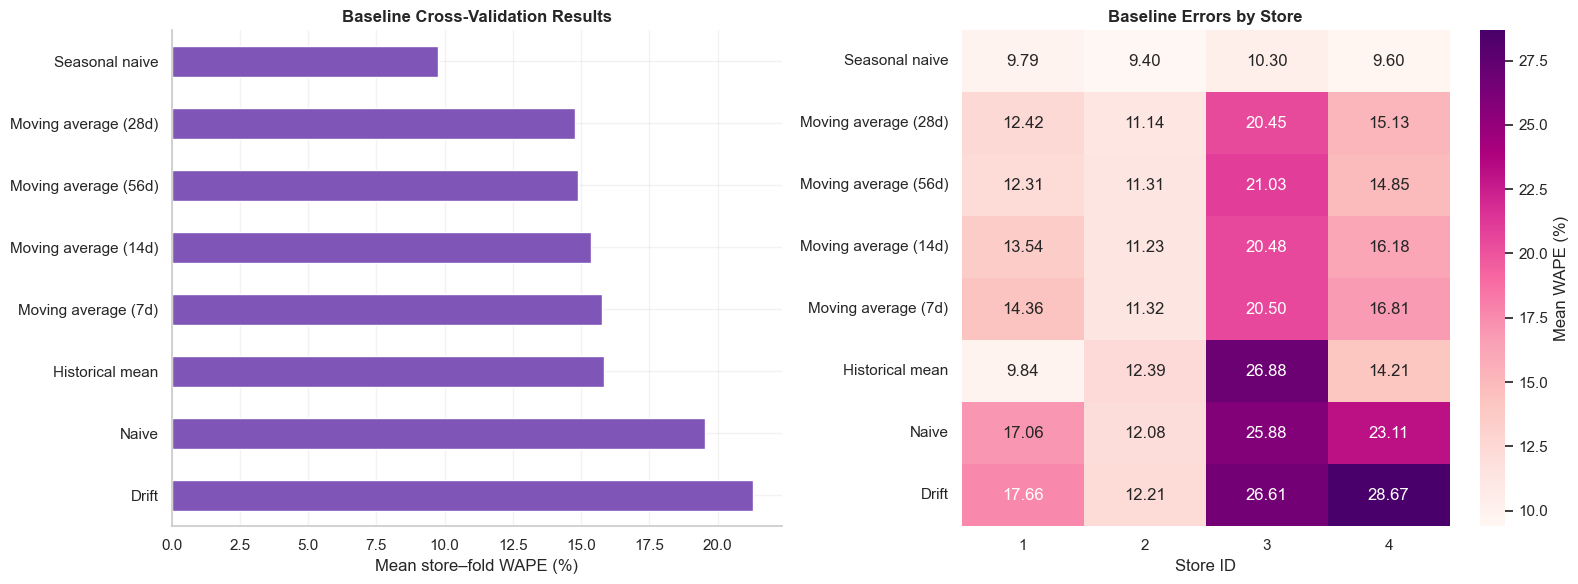

In [5]:
baseline_summary = (
    baseline_scores
    .groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        median_WAPE_pct=("WAPE_pct", "median"),
        worst_store_fold_WAPE_pct=("WAPE_pct", "max"),
        mean_MAE=("MAE", "mean"),
        mean_RMSE=("RMSE", "mean"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
    .sort_values("mean_WAPE_pct")
)

display(baseline_summary)

baseline_by_store = (
    baseline_scores
    .groupby(["model", "store_id"])["WAPE_pct"]
    .mean()
    .unstack("store_id")
    .reindex(baseline_summary.index)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

baseline_summary["mean_WAPE_pct"].sort_values().plot.barh(
    ax=axes[0],
    color=COLORS["purple"],
)
axes[0].invert_yaxis()
axes[0].set_title("Baseline Cross-Validation Results")
axes[0].set_xlabel("Mean store–fold WAPE (%)")
axes[0].set_ylabel("")

sns.heatmap(
    baseline_by_store,
    annot=True,
    fmt=".2f",
    cmap="RdPu",
    ax=axes[1],
    cbar_kws={"label": "Mean WAPE (%)"},
)
axes[1].set_title("Baseline Errors by Store")
axes[1].set_xlabel("Store ID")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

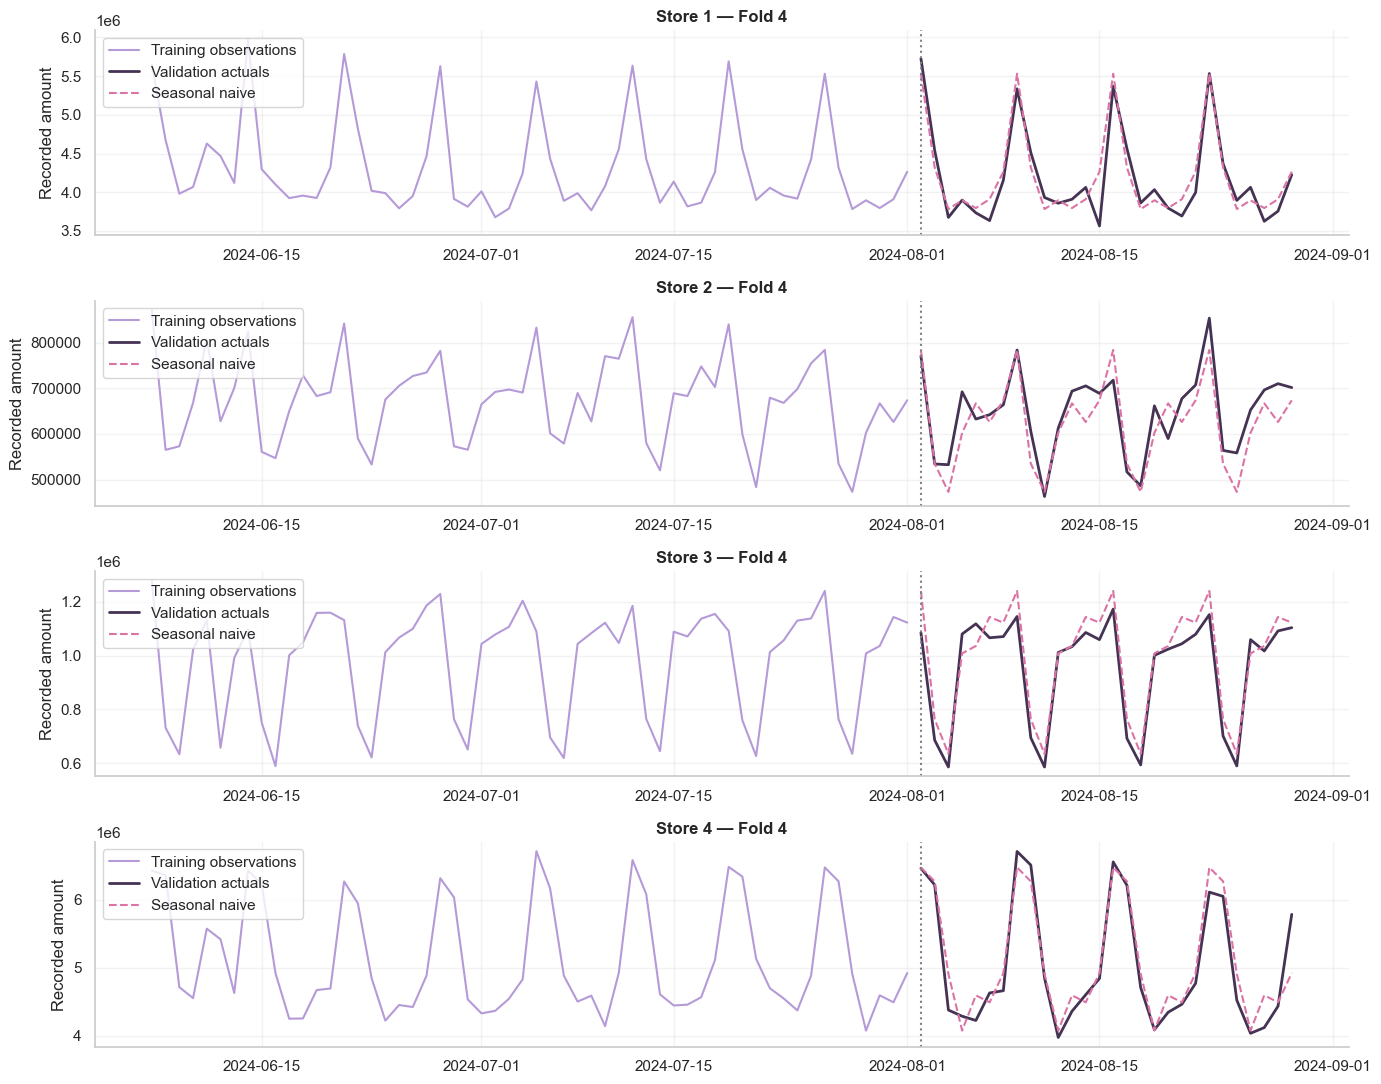

In [6]:
best_baseline = baseline_summary.index[0]
last_fold = int(cv_schedule["fold"].max())

models_to_plot = list(dict.fromkeys([
    best_baseline, "Seasonal naive"
]))

fig, axes = plt.subplots(
    len(store_series), 1,
    figsize=(14, 11),
)

for ax, store_id in zip(axes, sorted(store_series)):
    data = fold_data[(last_fold, store_id)]
    train = data["train"]
    valid = data["valid"]

    ax.plot(
        train.tail(56).index,
        train.tail(56),
        color=COLORS["lavender"],
        label="Training observations",
    )
    ax.plot(
        valid.index,
        valid,
        color=COLORS["dark"],
        linewidth=2,
        label="Validation actuals",
    )

    for model_name, color in zip(
        models_to_plot,
        [COLORS["pink"], COLORS["purple"]],
    ):
        selected = baseline_predictions.loc[
            baseline_predictions["fold"].eq(last_fold)
            & baseline_predictions["store_id"].eq(store_id)
            & baseline_predictions["model"].eq(model_name)
        ].sort_values("date")

        ax.plot(
            selected["date"],
            selected["prediction"],
            color=color,
            linestyle="--",
            label=model_name,
        )

    ax.axvline(
        valid.index.min(), color="grey", linestyle=":"
    )
    ax.set_title(f"Store {store_id} — Fold {last_fold}")
    ax.set_ylabel("Recorded amount")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

baseline_scores.to_csv(
    RESULTS_DIR / "baseline_cv_scores.csv", index=False
)
baseline_predictions.to_csv(
    RESULTS_DIR / "baseline_cv_predictions.csv", index=False
)

### Baseline findings

Seasonal naive achieves the lowest mean store–fold WAPE, 9.772%,
compared with 14.786% for the best moving-average baseline.
Preserving the most recent weekly pattern reduces mean WAPE by
approximately 34% relative to the 28-day moving-average forecast.

However, seasonal naive reaches 27.530% WAPE on its worst store–fold
combination. Weekly repetition is a useful benchmark, but does not
adequately explain every validation period.

Drift performs worst on average. Extrapolating the change between the
first and last training observations appears unsuitable for these
histories, particularly when endpoints are unusual.

## 3. Exponential Smoothing: Model Structure Comparison

We evaluate single exponential smoothing, Holt trend models, and
weekly Holt–Winters models on the same store–fold combinations.

We compare additive and multiplicative components where supported,
including damped trends. We also evaluate additive-component models
on the natural log scale.

Single smoothing has a level component, double smoothing adds trend,
and triple smoothing adds seasonality. We do not invent seasonal
components for methods that do not contain them.

Model parameters are estimated on training observations by minimizing
squared fitting errors. We compare model structures using validation WAPE.

For numerical conditioning, original-scale observations are expressed
in millions during fitting and forecasts are converted back.
Log forecasts are exponentiated without a mean-bias correction; they
are not assumed to estimate the conditional arithmetic mean.

In [7]:
import warnings

from statsmodels.tsa.holtwinters import ExponentialSmoothing

smoothing_specs = [
    dict(name="SES", family="single",
         trend=None, seasonal=None, damped=False),

    dict(name="Holt additive", family="double",
         trend="add", seasonal=None, damped=False),

    dict(name="Holt additive damped", family="double",
         trend="add", seasonal=None, damped=True),

    dict(name="Holt multiplicative", family="double",
         trend="mul", seasonal=None, damped=False),

    dict(name="Holt multiplicative damped", family="double",
         trend="mul", seasonal=None, damped=True),

    dict(name="HW additive", family="triple",
         trend="add", seasonal="add", damped=False),

    dict(name="HW additive damped", family="triple",
         trend="add", seasonal="add", damped=True),

    dict(name="HW multiplicative season", family="triple",
         trend="add", seasonal="mul", damped=False),

    dict(name="HW multiplicative season damped", family="triple",
         trend="add", seasonal="mul", damped=True),
]

# Log-scale alternatives use additive components in log units.
smoothing_candidates = []

for spec in smoothing_specs:
    smoothing_candidates.append({
        **spec, "scale": "original",
        "model": f"{spec['name']} | original",
    })

    if spec["trend"] != "mul" and spec["seasonal"] != "mul":
        smoothing_candidates.append({
            **spec, "scale": "log",
            "model": f"{spec['name']} | log",
        })


def fit_smoothing(train, spec, horizon):
    if not train.gt(0).all():
        raise ValueError(
            "These candidate specifications require positive training data."
        )

    transformed = (
        np.log(train)
        if spec["scale"] == "log"
        else train / 1_000_000
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        fitted = ExponentialSmoothing(
            transformed,
            trend=spec["trend"],
            damped_trend=spec["damped"],
            seasonal=spec["seasonal"],
            seasonal_periods=(
                SEASON_LENGTH if spec["seasonal"] else None
            ),
            initialization_method="estimated",
        ).fit(
            optimized=True,
            use_brute=True,
            remove_bias=False,
        )

        raw_forecast = np.asarray(
            fitted.forecast(horizon), dtype=float
        )

        prediction = (
            np.exp(raw_forecast)
            if spec["scale"] == "log"
            else raw_forecast * 1_000_000
        )

    if not np.isfinite(prediction).all():
        raise ValueError("Non-finite smoothing forecast.")

    optimizer = getattr(fitted, "mle_retvals", None)
    success = (
        optimizer.get("success", None)
        if optimizer is not None else None
    )

    if success is not None and not bool(success):
        raise RuntimeError("Smoothing optimizer did not converge.")

    warning_text = " | ".join(
        f"{type(w.message).__name__}: {w.message}"
        for w in caught
    )

    return fitted, prediction, warning_text

In [8]:
smoothing_score_rows = []
smoothing_prediction_parts = []
smoothing_issue_rows = []

# Retain last-fold fits for the component plots in the next block.
smoothing_last_fold_fits = {}
last_fold = int(cv_schedule["fold"].max())

for candidate_number, spec in enumerate(smoothing_candidates, start=1):
    print(
        f"{candidate_number}/{len(smoothing_candidates)}: "
        f"{spec['model']}"
    )

    for (fold, store_id), data in fold_data.items():
        try:
            fitted, prediction, warning_text = fit_smoothing(
                data["train"], spec, len(data["valid"])
            )
        except (ValueError, RuntimeError, FloatingPointError,
                np.linalg.LinAlgError) as error:
            smoothing_issue_rows.append({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "status": "failed",
                "message": str(error),
            })
            continue

        smoothing_score_rows.append({
            "model": spec["model"],
            "family": spec["family"],
            "scale": spec["scale"],
            "fold": fold,
            "store_id": store_id,
            **forecast_metrics(data["valid"].to_numpy(), prediction),
        })

        smoothing_prediction_parts.append(pd.DataFrame({
            "model": spec["model"],
            "fold": fold,
            "store_id": store_id,
            "date": data["valid"].index,
            "actual": data["valid"].to_numpy(),
            "prediction": prediction,
        }))

        if warning_text:
            smoothing_issue_rows.append({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "status": "warning",
                "message": warning_text,
            })

        if fold == last_fold:
            smoothing_last_fold_fits[(spec["model"], store_id)] = fitted

smoothing_scores = pd.DataFrame(smoothing_score_rows)
smoothing_predictions = (
    pd.concat(smoothing_prediction_parts, ignore_index=True)
    if smoothing_prediction_parts else pd.DataFrame()
)

smoothing_issues = pd.DataFrame(
    smoothing_issue_rows,
    columns=["model", "fold", "store_id", "status", "message"],
)

display(smoothing_issues)

if smoothing_scores.empty:
    raise RuntimeError("All smoothing fits failed; inspect the issue table.")

1/14: SES | original
2/14: SES | log
3/14: Holt additive | original
4/14: Holt additive | log
5/14: Holt additive damped | original
6/14: Holt additive damped | log
7/14: Holt multiplicative | original
8/14: Holt multiplicative damped | original
9/14: HW additive | original
10/14: HW additive | log
11/14: HW additive damped | original
12/14: HW additive damped | log
13/14: HW multiplicative season | original
14/14: HW multiplicative season damped | original


,model,fold,store_id,status,message
0,Holt multiplicative | original,1,3,warning,RuntimeWarning: overflow encountered in matmul...
1,Holt multiplicative | original,2,3,warning,RuntimeWarning: overflow encountered in matmul...
2,Holt multiplicative | original,3,2,warning,RuntimeWarning: overflow encountered in matmul
3,Holt multiplicative | original,3,3,warning,RuntimeWarning: overflow encountered in matmul...
4,Holt multiplicative | original,4,2,warning,RuntimeWarning: overflow encountered in matmul
5,Holt multiplicative | original,4,3,warning,RuntimeWarning: overflow encountered in matmul...


,model,family,scale,mean_WAPE_pct,worst_store_fold_WAPE_pct,mean_bias_pct,evaluated_store_folds,complete_cv
0,HW additive damped | log,triple,log,10.507,37.102,2.772,16,True
2,HW additive | log,triple,log,11.806,38.991,4.584,16,True
4,HW multiplicative season damped | original,triple,original,12.438,45.087,3.562,16,True
1,HW additive damped | original,triple,original,12.524,49.650,3.237,16,True
3,HW additive | original,triple,original,13.531,63.938,5.134,16,True
5,HW multiplicative season | original,triple,original,13.939,47.276,1.567,16,True
6,Holt additive damped | log,double,log,16.152,35.135,-0.490,16,True
12,SES | log,single,log,16.461,35.135,-2.025,16,True
8,Holt additive | log,double,log,17.112,37.224,3.721,16,True
7,Holt additive damped | original,double,original,18.160,52.207,4.078,16,True


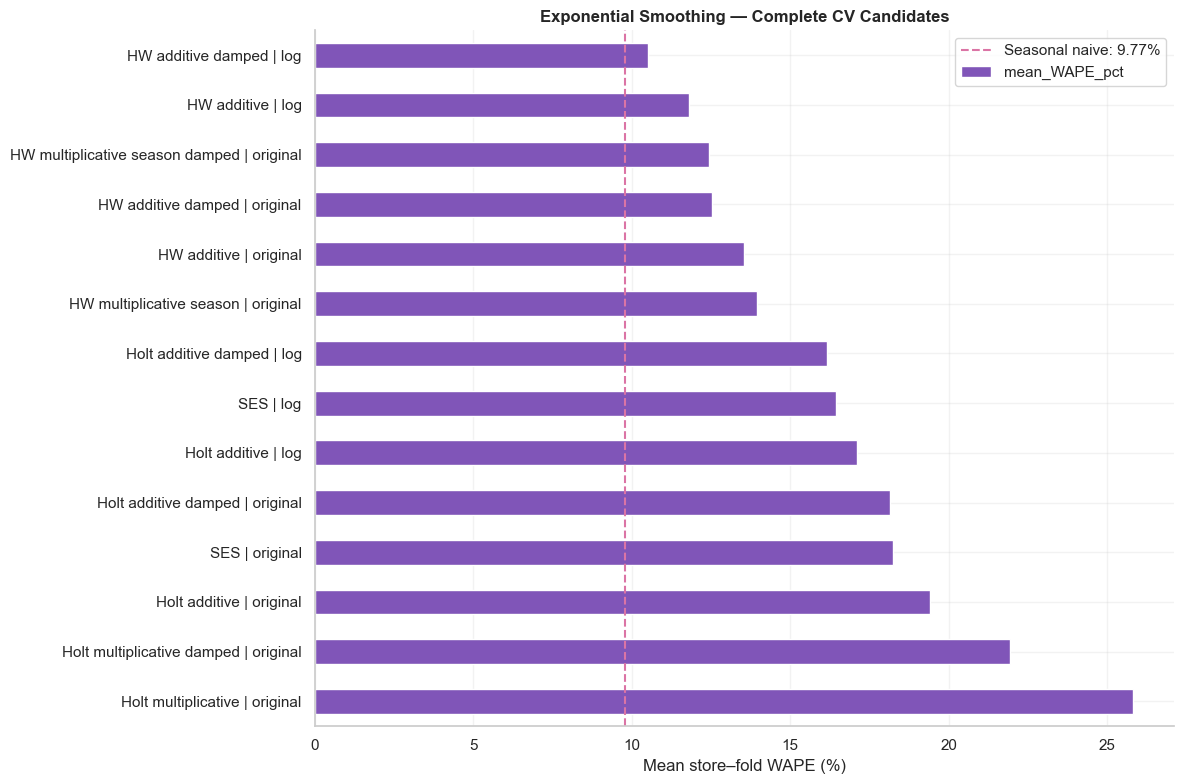

In [9]:
smoothing_summary = (
    smoothing_scores
    .groupby(["model", "family", "scale"])
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_store_fold_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
    .reset_index()
)

# Incomplete candidates must not win by skipping difficult folds.
smoothing_summary["complete_cv"] = (
    smoothing_summary["evaluated_store_folds"].eq(len(fold_data))
)

complete_smoothing = (
    smoothing_summary.loc[smoothing_summary["complete_cv"]]
    .sort_values("mean_WAPE_pct")
)

display(
    smoothing_summary.sort_values(
        ["complete_cv", "mean_WAPE_pct"],
        ascending=[False, True],
    )
)

if not complete_smoothing.empty:
    seasonal_naive_wape = baseline_summary.loc[
        "Seasonal naive", "mean_WAPE_pct"
    ]

    fig, ax = plt.subplots(figsize=(12, 8))

    (
        complete_smoothing.set_index("model")["mean_WAPE_pct"]
        .sort_values()
        .plot.barh(ax=ax, color=COLORS["purple"])
    )

    ax.invert_yaxis()
    ax.axvline(
        seasonal_naive_wape,
        color=COLORS["pink"],
        linestyle="--",
        label=f"Seasonal naive: {seasonal_naive_wape:.2f}%",
    )

    ax.set_title("Exponential Smoothing — Complete CV Candidates")
    ax.set_xlabel("Mean store–fold WAPE (%)")
    ax.set_ylabel("")
    ax.legend()
    plt.tight_layout()
    plt.show()

smoothing_scores.to_csv(
    RESULTS_DIR / "smoothing_cv_scores.csv", index=False
)
smoothing_predictions.to_csv(
    RESULTS_DIR / "smoothing_cv_predictions.csv", index=False
)
smoothing_issues.to_csv(
    RESULTS_DIR / "smoothing_fit_issues.csv", index=False
)

### Smoothing comparison findings

The best smoothing candidate is damped additive Holt–Winters on the
log scale, with mean WAPE of 10.507%. It does not outperform seasonal
naive, which achieves 9.772%.

Within the tested Holt–Winters specifications, log transformation and
trend damping improve average validation performance. However, the
best smoothing candidate still reaches 37.102% WAPE on its worst
store–fold combination.

Multiplicative Holt trend fits produced overflow warnings during
optimization in several combinations. Their final forecasts were finite
and the optimizer reported success, but these warnings indicate numerical
instability and remain part of the model assessment.

Greater model complexity has not yet improved on weekly repetition.
We next inspect fitted components and store–fold errors.

## 4. Smoothing Components and Error Breakdown

We inspect the lowest-CV-WAPE specification within each smoothing family
using its stored last-fold fits for every store.

Single smoothing contains level only. Double smoothing contains level
and trend. Triple smoothing additionally contains weekly seasonality.

Components are displayed in fitting units: natural log units for log-scale
models and millions of source monetary units for original-scale models.
They should not be interpreted as additive monetary contributions after
exponentiation.

These plots describe fitted states. Their visual smoothness is not evidence
of forecast accuracy, and in-sample fitted values are not cross-validation
predictions.

,model,mean_WAPE_pct,worst_store_fold_WAPE_pct
family,,,
single,SES | log,16.461,35.135
double,Holt additive damped | log,16.152,35.135
triple,HW additive damped | log,10.507,37.102


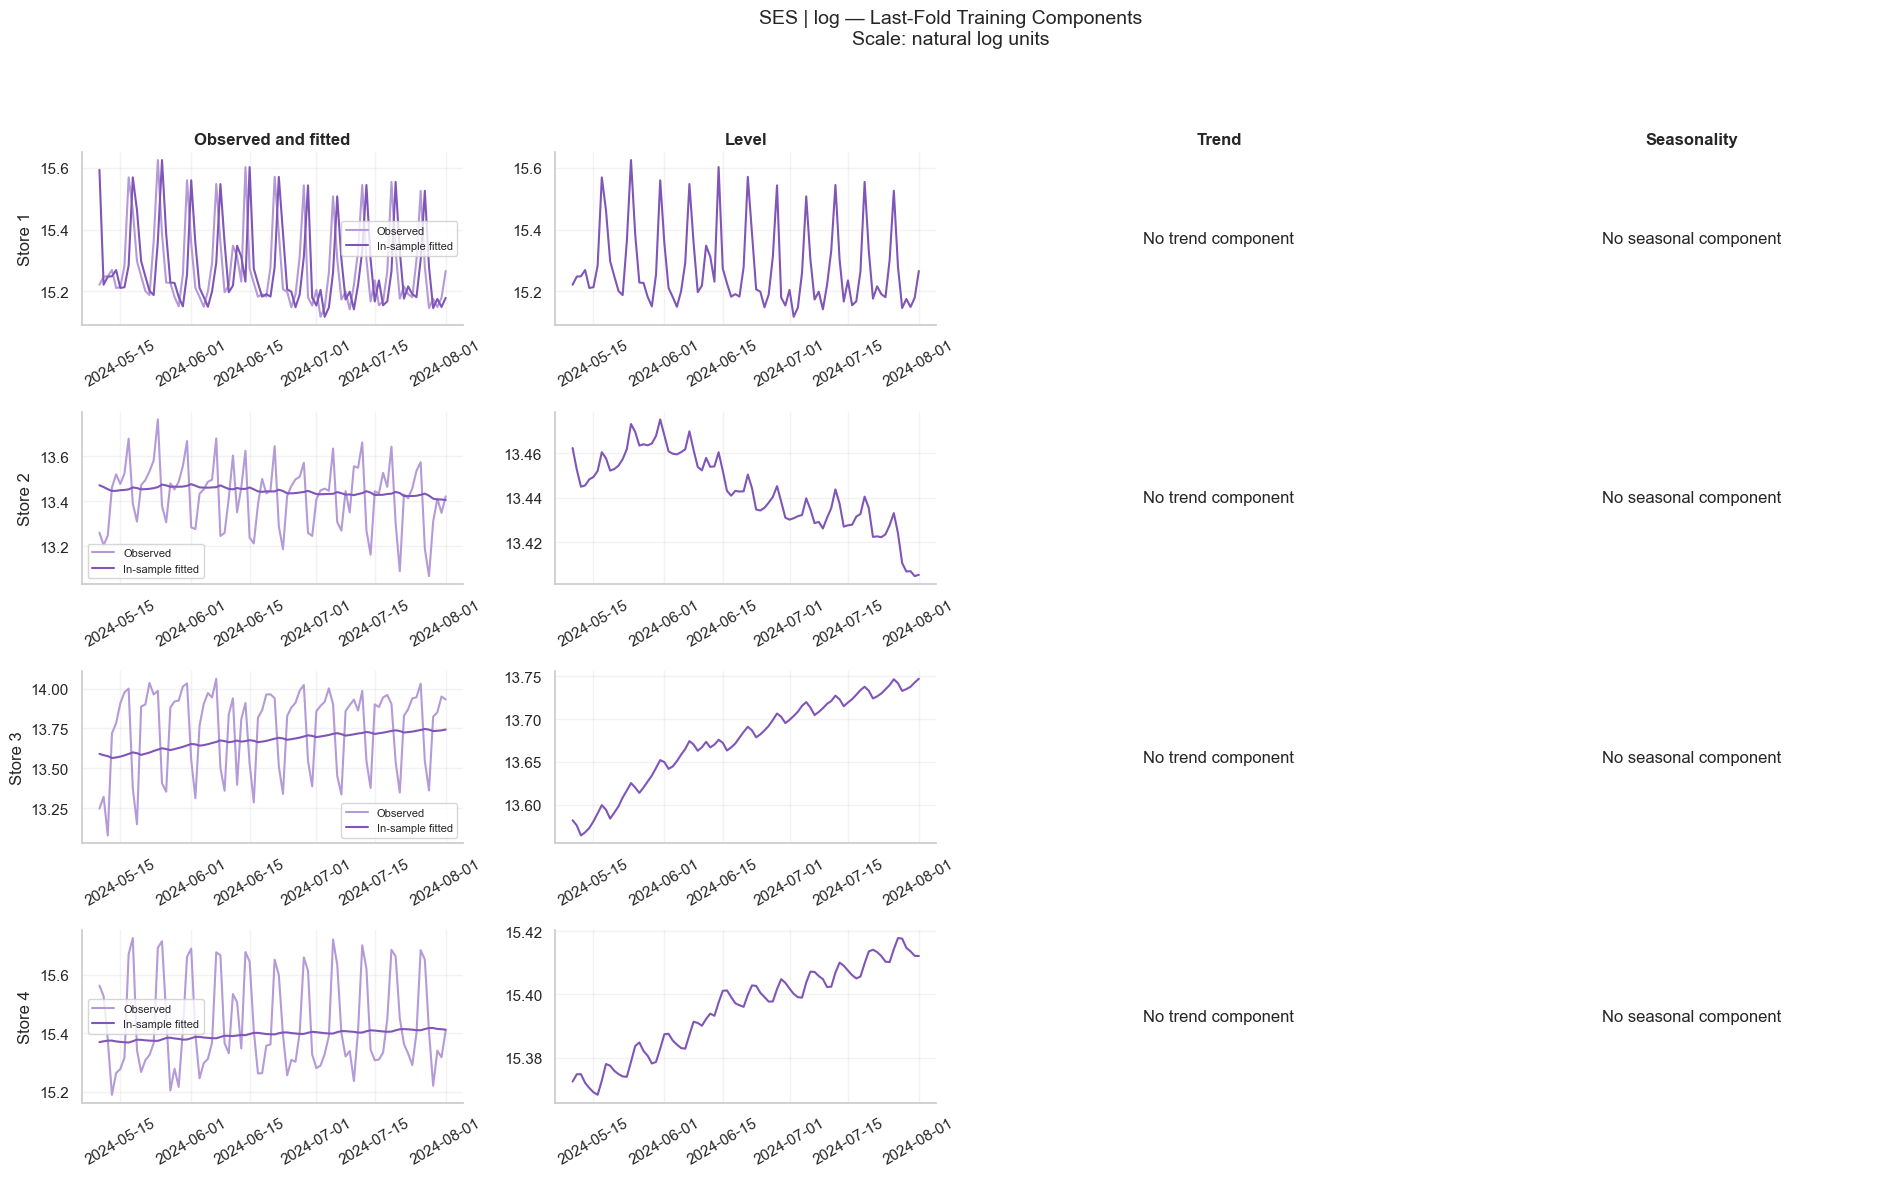

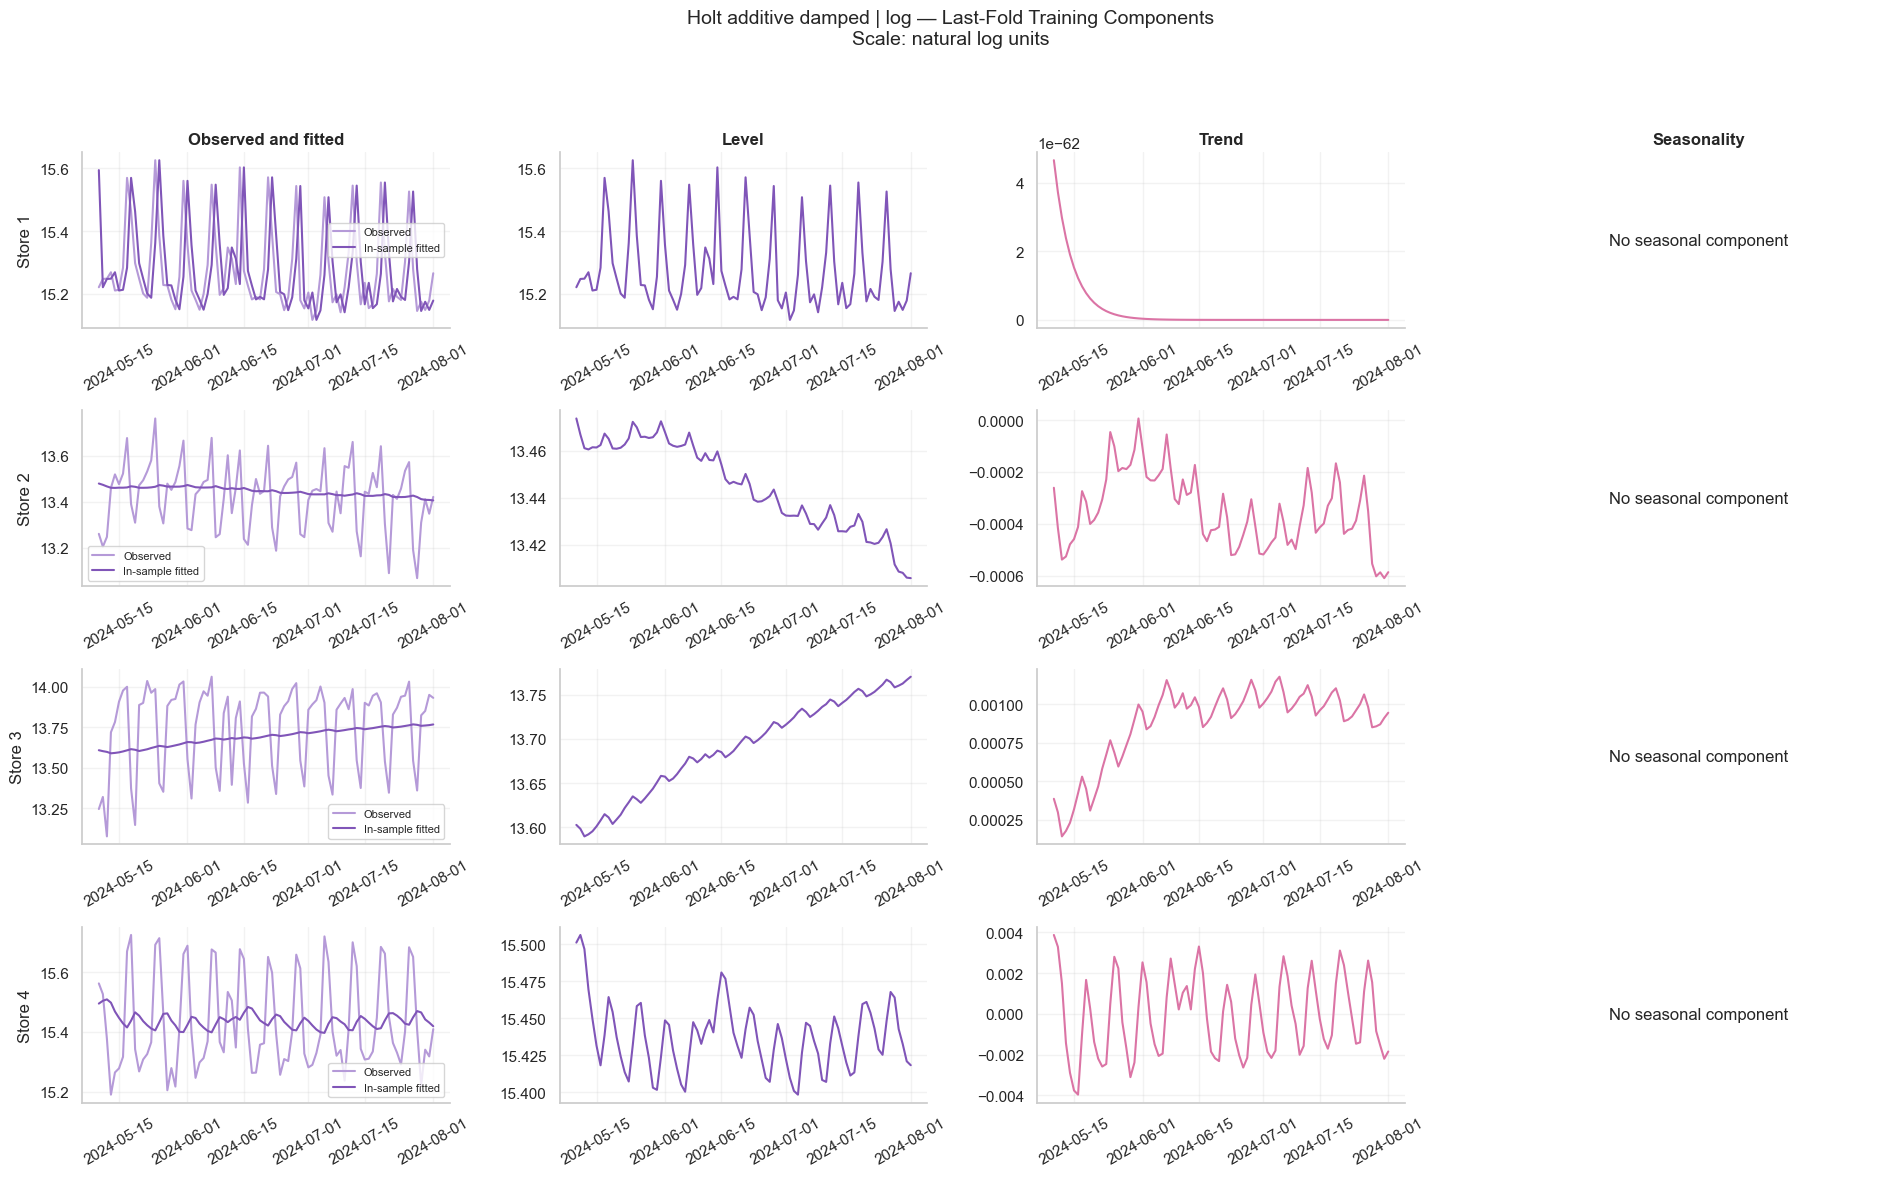

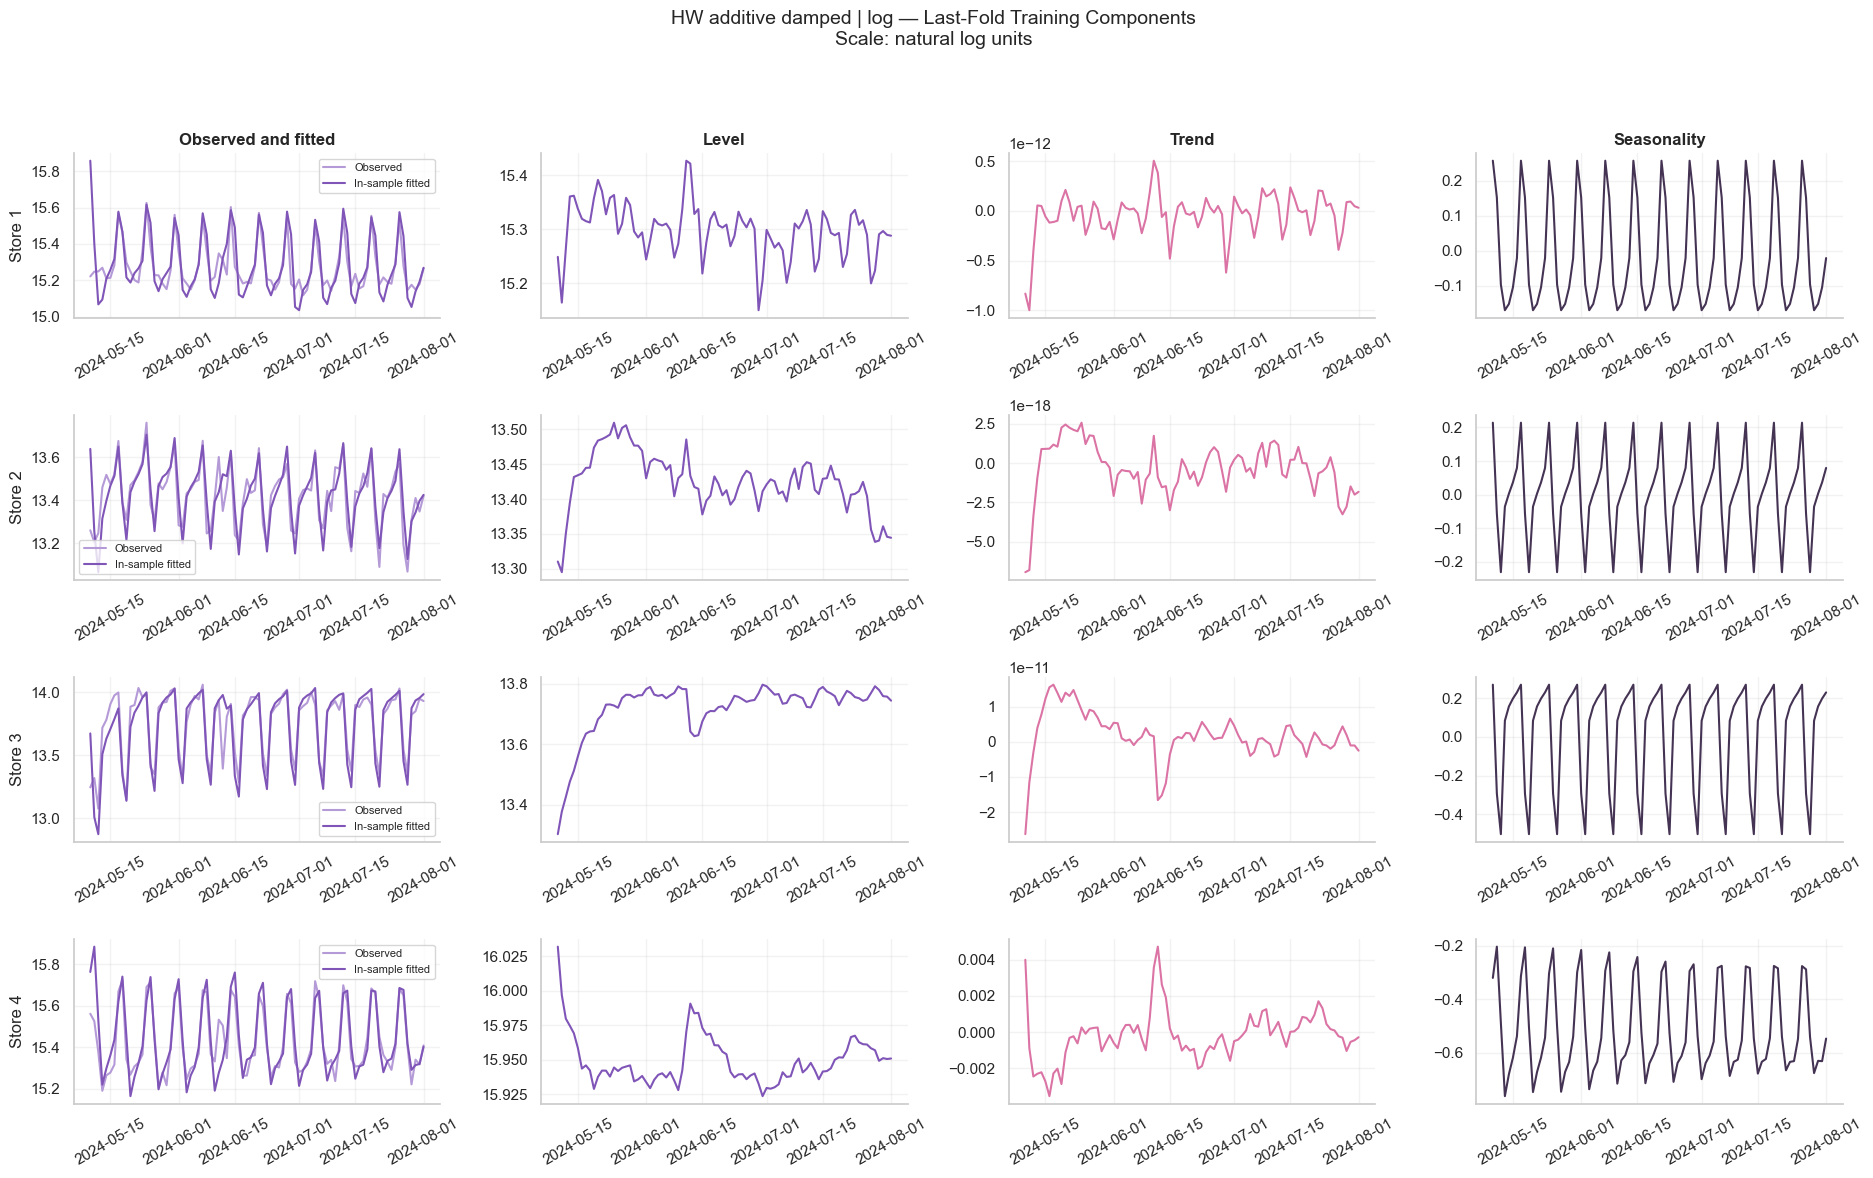

,family,model,store_id,fold,alpha,beta,gamma,phi
0,single,SES | log,1,4,1.000,NaN,NaN,NaN
1,single,SES | log,2,4,0.037,NaN,NaN,NaN
2,single,SES | log,3,4,0.023,NaN,NaN,NaN
3,single,SES | log,4,4,0.015,NaN,NaN,NaN
4,double,Holt additive damped | log,1,4,1.000,0.000,NaN,0.800
5,double,Holt additive damped | log,2,4,0.024,0.024,NaN,0.977
6,double,Holt additive damped | log,3,4,0.017,0.017,NaN,0.985
7,double,Holt additive damped | log,4,4,0.093,0.093,NaN,0.800
8,triple,HW additive damped | log,1,4,0.551,0.000,0.000,0.800
9,triple,HW additive damped | log,2,4,0.303,0.000,0.000,0.879


In [10]:
best_by_family = (
    complete_smoothing
    .sort_values(["mean_WAPE_pct", "model"])
    .groupby("family", sort=False)
    .head(1)
    .set_index("family")
    .reindex(["single", "double", "triple"])
)

if best_by_family["model"].isna().any():
    raise ValueError("A smoothing family has no complete CV candidate.")

display(best_by_family[
    ["model", "mean_WAPE_pct", "worst_store_fold_WAPE_pct"]
])

candidate_lookup = {
    spec["model"]: spec
    for spec in smoothing_candidates
}

parameter_rows = []

for family in ["single", "double", "triple"]:
    model_name = best_by_family.loc[family, "model"]
    spec = candidate_lookup[model_name]

    fig, axes = plt.subplots(
        len(store_series), 4,
        figsize=(19, 12),
        squeeze=False,
    )

    fitting_units = (
        "natural log units"
        if spec["scale"] == "log"
        else "millions of source monetary units"
    )

    for row, store_id in enumerate(sorted(store_series)):
        fitted = smoothing_last_fold_fits[(model_name, store_id)]
        train = fold_data[(last_fold, store_id)]["train"]

        observed_fit_scale = (
            np.log(train)
            if spec["scale"] == "log"
            else train / 1_000_000
        )

        # Display the last 84 training days.
        dates = train.index[-84:]
        n_show = len(dates)

        axes[row, 0].plot(
            dates,
            observed_fit_scale.iloc[-n_show:],
            color=COLORS["lavender"],
            label="Observed",
        )
        axes[row, 0].plot(
            dates,
            np.asarray(fitted.fittedvalues)[-n_show:],
            color=COLORS["purple"],
            label="In-sample fitted",
        )
        axes[row, 0].set_ylabel(f"Store {store_id}")
        axes[row, 0].legend(fontsize=8)

        axes[row, 1].plot(
            dates,
            np.asarray(fitted.level)[-n_show:],
            color=COLORS["purple"],
        )

        if spec["trend"] is not None:
            axes[row, 2].plot(
                dates,
                np.asarray(fitted.trend)[-n_show:],
                color=COLORS["pink"],
            )
        else:
            axes[row, 2].text(
                0.5, 0.5, "No trend component",
                ha="center", va="center",
                transform=axes[row, 2].transAxes,
            )
            axes[row, 2].set_axis_off()

        if spec["seasonal"] is not None:
            axes[row, 3].plot(
                dates,
                np.asarray(fitted.season)[-n_show:],
                color=COLORS["dark"],
            )
        else:
            axes[row, 3].text(
                0.5, 0.5, "No seasonal component",
                ha="center", va="center",
                transform=axes[row, 3].transAxes,
            )
            axes[row, 3].set_axis_off()

        for ax in axes[row]:
            ax.tick_params(axis="x", rotation=30)

        params = fitted.params

        parameter_rows.append({
            "family": family,
            "model": model_name,
            "store_id": store_id,
            "fold": last_fold,
            "alpha": params.get("smoothing_level", np.nan),
            "beta": params.get("smoothing_trend", np.nan),
            "gamma": params.get("smoothing_seasonal", np.nan),
            "phi": params.get("damping_trend", np.nan),
        })

    for column, title in enumerate([
        "Observed and fitted", "Level", "Trend", "Seasonality"
    ]):
        axes[0, column].set_title(title)

    fig.suptitle(
        f"{model_name} — Last-Fold Training Components\n"
        f"Scale: {fitting_units}",
        fontsize=14,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

component_parameters = pd.DataFrame(parameter_rows)
display(component_parameters)

component_parameters.to_csv(
    RESULTS_DIR / "smoothing_component_parameters.csv",
    index=False,
)

,fold,store_id,smoothing_WAPE_pct,seasonal_naive_WAPE_pct,difference_pp
1,1,2,7.064,21.040,-13.976
3,1,4,22.675,26.010,-3.335
14,4,3,5.275,5.954,-0.679
9,3,2,5.631,6.036,-0.406
6,2,3,6.409,6.734,-0.324
13,4,2,6.027,6.243,-0.216
11,3,4,4.222,4.088,0.134
15,4,4,4.294,4.119,0.174
8,3,1,5.091,3.968,1.123
5,2,2,5.530,4.269,1.262


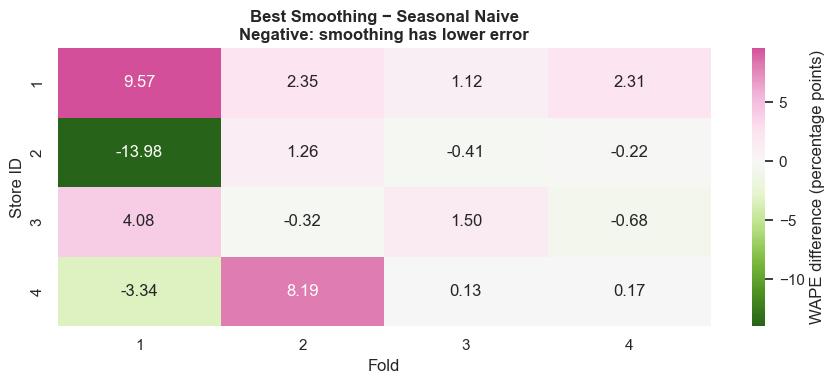

In [11]:
best_smoothing_name = complete_smoothing.iloc[0]["model"]

smoothing_vs_baseline = (
    smoothing_scores.loc[
        smoothing_scores["model"].eq(best_smoothing_name),
        ["fold", "store_id", "WAPE_pct"],
    ]
    .rename(columns={"WAPE_pct": "smoothing_WAPE_pct"})
    .merge(
        baseline_scores.loc[
            baseline_scores["model"].eq("Seasonal naive"),
            ["fold", "store_id", "WAPE_pct"],
        ].rename(columns={"WAPE_pct": "seasonal_naive_WAPE_pct"}),
        on=["fold", "store_id"],
        validate="one_to_one",
    )
)

smoothing_vs_baseline["difference_pp"] = (
    smoothing_vs_baseline["smoothing_WAPE_pct"]
    - smoothing_vs_baseline["seasonal_naive_WAPE_pct"]
)

display(smoothing_vs_baseline.sort_values("difference_pp"))

fig, ax = plt.subplots(figsize=(9, 4))

sns.heatmap(
    smoothing_vs_baseline.pivot(
        index="store_id",
        columns="fold",
        values="difference_pp",
    ),
    annot=True,
    fmt=".2f",
    cmap="PiYG_r",
    center=0,
    ax=ax,
    cbar_kws={"label": "WAPE difference (percentage points)"},
)

ax.set_title(
    "Best Smoothing − Seasonal Naive\n"
    "Negative: smoothing has lower error"
)
ax.set_xlabel("Fold")
ax.set_ylabel("Store ID")
plt.tight_layout()
plt.show()

### Component and store–fold findings

The best triple-smoothing candidate improves on seasonal naive in 6 of
16 store–fold combinations, but its larger losses elsewhere result in
higher mean WAPE.

The largest improvement occurs for store 2 in fold 1: WAPE decreases
from 21.040% to 7.064%. The largest deterioration occurs for store 1
in fold 1: WAPE increases from 27.530% to 37.102%.

For stores 1–3, the selected triple model has seasonal smoothing
parameters displayed as 0.000. This indicates little seasonal updating,
not the absence of an estimated seasonal component.

Parameters near optimization boundaries require caution. We assess
their usefulness through validation forecasts rather than interpreting
them as direct evidence about the business process.

## 5. Autoregressive and Seasonal Models

We compare a predefined set of AR, MA, ARMA, ARIMA, and weekly SARIMA
specifications on original and natural-log scales.

Orders are deliberately small. The seasonal period is seven days,
motivated by the weekday patterns observed during EDA.

Differencing is performed inside the model, and forecasts are returned
to the level scale. Log-scale forecasts are exponentiated without
mean-bias correction.

We estimate parameters separately within every training fold and generate
the complete validation horizon without updates from validation targets.

We record optimizer failures and warnings. Candidates must produce valid,
converged forecasts for all 16 store–fold combinations to enter the main
ranking.

In [12]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

arima_structures = [
    ("AR(1)", (1, 0, 0), (0, 0, 0, 0)),
    ("AR(2)", (2, 0, 0), (0, 0, 0, 0)),
    ("MA(1)", (0, 0, 1), (0, 0, 0, 0)),
    ("MA(2)", (0, 0, 2), (0, 0, 0, 0)),
    ("ARMA(1,1)", (1, 0, 1), (0, 0, 0, 0)),
    ("ARIMA(1,1,0)", (1, 1, 0), (0, 0, 0, 0)),
    ("ARIMA(0,1,1)", (0, 1, 1), (0, 0, 0, 0)),
    ("ARIMA(1,1,1)", (1, 1, 1), (0, 0, 0, 0)),
    ("SARIMA(1,0,0)(1,0,0,7)", (1, 0, 0), (1, 0, 0, 7)),
    ("SARIMA(1,0,0)(0,1,1,7)", (1, 0, 0), (0, 1, 1, 7)),
    ("SARIMA(0,1,1)(0,1,1,7)", (0, 1, 1), (0, 1, 1, 7)),
]

arima_candidates = [
    {
        "model": f"{name} | {scale}",
        "order": order,
        "seasonal_order": seasonal_order,
        "scale": scale,
    }
    for name, order, seasonal_order in arima_structures
    for scale in ["original", "log"]
]


def fit_arima_candidate(train, spec, horizon):
    if spec["scale"] == "log":
        if not train.gt(0).all():
            raise ValueError("Log scale requires positive observations.")
        transformed = np.log(train)
    else:
        transformed = train / 1_000_000

    has_differencing = (
        spec["order"][1] > 0
        or spec["seasonal_order"][1] > 0
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        model = SARIMAX(
            transformed,
            order=spec["order"],
            seasonal_order=spec["seasonal_order"],
            # Intercept for undifferenced models; no drift otherwise.
            trend="n" if has_differencing else "c",
            enforce_stationarity=True,
            enforce_invertibility=True,
        )

        fitted = model.fit(
            method="lbfgs",
            maxiter=300,
            disp=False,
        )

        if not fitted.mle_retvals.get("converged", False):
            raise RuntimeError("Optimizer did not converge.")

        forecast = np.asarray(
            fitted.forecast(horizon), dtype=float
        )

        prediction = (
            np.exp(forecast)
            if spec["scale"] == "log"
            else forecast * 1_000_000
        )

    if (
        prediction.shape != (horizon,)
        or not np.isfinite(prediction).all()
    ):
        raise ValueError("Invalid forecast.")

    warning_text = " | ".join(
        f"{type(w.message).__name__}: {w.message}"
        for w in caught
    )

    return fitted, prediction, warning_text

In [13]:
arima_score_rows = []
arima_prediction_parts = []
arima_issue_rows = []
arima_last_fold_fits = {}

for number, spec in enumerate(arima_candidates, start=1):
    print(f"{number}/{len(arima_candidates)}: {spec['model']}")

    for (fold, store_id), data in fold_data.items():
        try:
            fitted, prediction, warning_text = fit_arima_candidate(
                data["train"], spec, len(data["valid"])
            )
        except (
            ValueError, RuntimeError, FloatingPointError,
            np.linalg.LinAlgError,
        ) as error:
            arima_issue_rows.append({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "status": "failed",
                "message": str(error),
            })
            continue

        arima_score_rows.append({
            "model": spec["model"],
            "fold": fold,
            "store_id": store_id,
            **forecast_metrics(data["valid"].to_numpy(), prediction),
        })

        arima_prediction_parts.append(pd.DataFrame({
            "model": spec["model"],
            "fold": fold,
            "store_id": store_id,
            "date": data["valid"].index,
            "actual": data["valid"].to_numpy(),
            "prediction": prediction,
        }))

        if warning_text:
            arima_issue_rows.append({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "status": "warning",
                "message": warning_text,
            })

        if fold == last_fold:
            arima_last_fold_fits[(spec["model"], store_id)] = fitted

arima_scores = pd.DataFrame(arima_score_rows)
arima_predictions = (
    pd.concat(arima_prediction_parts, ignore_index=True)
    if arima_prediction_parts else pd.DataFrame()
)
arima_issues = pd.DataFrame(
    arima_issue_rows,
    columns=["model", "fold", "store_id", "status", "message"],
)

display(arima_issues)

arima_scores.to_csv(
    RESULTS_DIR / "arima_cv_scores.csv", index=False
)
arima_predictions.to_csv(
    RESULTS_DIR / "arima_cv_predictions.csv", index=False
)
arima_issues.to_csv(
    RESULTS_DIR / "arima_fit_issues.csv", index=False
)

if arima_scores.empty:
    raise RuntimeError("No successful fits; inspect arima_issues.")

1/22: AR(1) | original
2/22: AR(1) | log
3/22: AR(2) | original
4/22: AR(2) | log
5/22: MA(1) | original
6/22: MA(1) | log
7/22: MA(2) | original
8/22: MA(2) | log
9/22: ARMA(1,1) | original
10/22: ARMA(1,1) | log
11/22: ARIMA(1,1,0) | original
12/22: ARIMA(1,1,0) | log
13/22: ARIMA(0,1,1) | original
14/22: ARIMA(0,1,1) | log
15/22: ARIMA(1,1,1) | original
16/22: ARIMA(1,1,1) | log
17/22: SARIMA(1,0,0)(1,0,0,7) | original
18/22: SARIMA(1,0,0)(1,0,0,7) | log
19/22: SARIMA(1,0,0)(0,1,1,7) | original
20/22: SARIMA(1,0,0)(0,1,1,7) | log
21/22: SARIMA(0,1,1)(0,1,1,7) | original
22/22: SARIMA(0,1,1)(0,1,1,7) | log


,model,fold,store_id,status,message
0,AR(1) | log,4,1,failed,Optimizer did not converge.
1,AR(1) | log,4,2,failed,Optimizer did not converge.
2,AR(2) | log,2,3,failed,Optimizer did not converge.
3,"ARMA(1,1) | log",3,2,failed,Optimizer did not converge.
4,"ARIMA(1,1,0) | original",2,2,failed,Optimizer did not converge.
5,"SARIMA(1,0,0)(1,0,0,7) | log",1,1,warning,UserWarning: Non-stationary starting seasonal ...
6,"SARIMA(1,0,0)(1,0,0,7) | log",1,2,warning,UserWarning: Non-stationary starting seasonal ...
7,"SARIMA(1,0,0)(1,0,0,7) | log",1,4,warning,UserWarning: Non-stationary starting seasonal ...
8,"SARIMA(1,0,0)(1,0,0,7) | log",2,1,warning,UserWarning: Non-stationary starting seasonal ...
9,"SARIMA(1,0,0)(1,0,0,7) | log",2,2,warning,UserWarning: Non-stationary starting seasonal ...


In [14]:
comparison_scores = pd.concat(
    [
        baseline_scores[[
            "model", "fold", "store_id", "WAPE_pct", "bias_pct"
        ]],
        smoothing_scores[[
            "model", "fold", "store_id", "WAPE_pct", "bias_pct"
        ]],
        arima_scores[[
            "model", "fold", "store_id", "WAPE_pct", "bias_pct"
        ]],
    ],
    ignore_index=True,
)

classical_comparison = (
    comparison_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
)

classical_comparison["complete_cv"] = (
    classical_comparison["evaluated_store_folds"].eq(len(fold_data))
)

display(
    classical_comparison.sort_values(
        ["complete_cv", "mean_WAPE_pct"],
        ascending=[False, True],
    )
)

classical_comparison.to_csv(
    RESULTS_DIR / "classical_cv_comparison.csv"
)

,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds,complete_cv
model,,,,,
"SARIMA(1,0,0)(0,1,1,7) | log",8.046,20.465,-0.952,16,True
"SARIMA(1,0,0)(0,1,1,7) | original",8.121,20.009,-0.408,16,True
Seasonal naive,9.772,27.530,1.704,16,True
HW additive damped | log,10.507,37.102,2.772,16,True
HW additive | log,11.806,38.991,4.584,16,True
"SARIMA(1,0,0)(1,0,0,7) | original",12.121,25.121,-4.214,16,True
HW multiplicative season damped | original,12.438,45.087,3.562,16,True
"SARIMA(0,1,1)(0,1,1,7) | log",12.454,50.009,4.860,16,True
HW additive damped | original,12.524,49.650,3.237,16,True


### ARIMA-family findings

SARIMA(1,0,0)(0,1,1,7) on the log scale achieves the lowest mean
store–fold WAPE so far: 8.046%, compared with 9.772% for seasonal naive.
This corresponds to an approximately 17.7% relative reduction.

The same specification on the original scale achieves 8.121%.
The difference between scales is small, while the original-scale model
has a slightly lower worst-case WAPE.

Within this candidate set, weekly seasonal differencing is more useful
than non-seasonal differencing alone. This result supports modelling
the weekly structure, but does not establish that every series requires
the same differencing order.

Five specifications have incomplete cross-validation because some fits
did not converge. We exclude them from the main ranking rather than
comparing averages calculated on fewer combinations.

These are model-selection results on development data. The holdout
remains unopened.

## 6. Decomposition-Based Forecasting versus Differencing

We compare additive STL decomposition on the original scale with
log-STL decomposition, which represents multiplicative structure
after exponentiation.

Each decomposition is fitted separately to training data only.
We extrapolate the trend using a linear fit to its last 28 or 56 days,
repeat the final seven seasonal components, and forecast the residual
using AR(1) or ARMA(1,1).

The complete forecast combines the extrapolated components and the
residual forecast. Its validation error therefore assesses the entire
pipeline, including the chosen trend extrapolation rule.

We compare these pipelines with the previously evaluated differenced
models. We do not use decomposition components calculated on validation
or holdout observations.

In [15]:
from statsmodels.tsa.seasonal import STL

decomposition_candidates = [
    {
        "model": f"STL+{residual_name} | {scale} | trend{window}d",
        "scale": scale,
        "trend_window": window,
        "residual_order": order,
    }
    for scale in ["original", "log"]
    for window in [28, 56]
    for residual_name, order in [
        ("AR(1)", (1, 0, 0)),
        ("ARMA(1,1)", (1, 0, 1)),
    ]
]


def fit_decomposition_forecast(train, spec, horizon):
    if spec["scale"] == "log":
        if not train.gt(0).all():
            raise ValueError("Log decomposition requires positive data.")
        transformed = np.log(train)
    else:
        transformed = train / 1_000_000

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        decomposition = STL(
            transformed,
            period=SEASON_LENGTH,
            seasonal=13,
            robust=True,
        ).fit()

        window = spec["trend_window"]

        # Training trend only; extrapolate from the end of training.
        x = np.arange(window, dtype=float)
        slope, intercept = np.polyfit(
            x,
            np.asarray(decomposition.trend)[-window:],
            deg=1,
        )
        trend_forecast = (
            intercept + slope * np.arange(window, window + horizon)
        )

        seasonal_forecast = np.resize(
            np.asarray(decomposition.seasonal)[-SEASON_LENGTH:],
            horizon,
        )

        residual_fit = SARIMAX(
            decomposition.resid,
            order=spec["residual_order"],
            trend="c",
            enforce_stationarity=True,
            enforce_invertibility=True,
        ).fit(maxiter=300, disp=False)

        if not residual_fit.mle_retvals.get("converged", False):
            raise RuntimeError("Residual model did not converge.")

        combined_forecast = (
            trend_forecast
            + seasonal_forecast
            + np.asarray(residual_fit.forecast(horizon))
        )

        prediction = (
            np.exp(combined_forecast)
            if spec["scale"] == "log"
            else combined_forecast * 1_000_000
        )

    if not np.isfinite(prediction).all():
        raise ValueError("Non-finite decomposition forecast.")

    warning_text = " | ".join(
        f"{type(w.message).__name__}: {w.message}"
        for w in caught
    )

    return prediction, warning_text

In [16]:
decomposition_score_rows = []
decomposition_prediction_parts = []
decomposition_issue_rows = []

for number, spec in enumerate(decomposition_candidates, start=1):
    print(
        f"{number}/{len(decomposition_candidates)}: {spec['model']}"
    )

    for (fold, store_id), data in fold_data.items():
        try:
            prediction, warning_text = fit_decomposition_forecast(
                data["train"], spec, len(data["valid"])
            )
        except (
            ValueError, RuntimeError, FloatingPointError,
            np.linalg.LinAlgError,
        ) as error:
            decomposition_issue_rows.append({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "status": "failed",
                "message": str(error),
            })
            continue

        decomposition_score_rows.append({
            "model": spec["model"],
            "fold": fold,
            "store_id": store_id,
            **forecast_metrics(data["valid"].to_numpy(), prediction),
        })

        decomposition_prediction_parts.append(pd.DataFrame({
            "model": spec["model"],
            "fold": fold,
            "store_id": store_id,
            "date": data["valid"].index,
            "actual": data["valid"].to_numpy(),
            "prediction": prediction,
        }))

        if warning_text:
            decomposition_issue_rows.append({
                "model": spec["model"],
                "fold": fold,
                "store_id": store_id,
                "status": "warning",
                "message": warning_text,
            })

decomposition_scores = pd.DataFrame(decomposition_score_rows)
decomposition_predictions = (
    pd.concat(decomposition_prediction_parts, ignore_index=True)
    if decomposition_prediction_parts else pd.DataFrame()
)
decomposition_issues = pd.DataFrame(
    decomposition_issue_rows,
    columns=["model", "fold", "store_id", "status", "message"],
)

display(decomposition_issues)

decomposition_scores.to_csv(
    RESULTS_DIR / "decomposition_cv_scores.csv", index=False
)
decomposition_predictions.to_csv(
    RESULTS_DIR / "decomposition_cv_predictions.csv", index=False
)
decomposition_issues.to_csv(
    RESULTS_DIR / "decomposition_fit_issues.csv", index=False
)

if decomposition_scores.empty:
    raise RuntimeError("No successful decomposition forecasts.")

1/8: STL+AR(1) | original | trend28d
2/8: STL+ARMA(1,1) | original | trend28d
3/8: STL+AR(1) | original | trend56d
4/8: STL+ARMA(1,1) | original | trend56d
5/8: STL+AR(1) | log | trend28d
6/8: STL+ARMA(1,1) | log | trend28d
7/8: STL+AR(1) | log | trend56d
8/8: STL+ARMA(1,1) | log | trend56d


,model,fold,store_id,status,message
0,"STL+ARMA(1,1) | original | trend28d",1,2,failed,Residual model did not converge.
1,"STL+ARMA(1,1) | original | trend56d",1,2,failed,Residual model did not converge.


In [17]:
all_classical_scores = pd.concat(
    [
        baseline_scores,
        smoothing_scores,
        arima_scores,
        decomposition_scores,
    ],
    ignore_index=True,
)

assert not all_classical_scores.duplicated(
    ["model", "fold", "store_id"]
).any()

all_classical_summary = (
    all_classical_scores.groupby("model")
    .agg(
        mean_WAPE_pct=("WAPE_pct", "mean"),
        worst_WAPE_pct=("WAPE_pct", "max"),
        mean_bias_pct=("bias_pct", "mean"),
        evaluated_store_folds=("WAPE_pct", "count"),
    )
)

all_classical_summary["complete_cv"] = (
    all_classical_summary["evaluated_store_folds"].eq(len(fold_data))
)

complete_classical_summary = (
    all_classical_summary.loc[all_classical_summary["complete_cv"]]
    .sort_values("mean_WAPE_pct")
)

display(complete_classical_summary.head(20))

all_classical_summary.to_csv(
    RESULTS_DIR / "classical_cv_comparison.csv"
)

,mean_WAPE_pct,worst_WAPE_pct,mean_bias_pct,evaluated_store_folds,complete_cv
model,,,,,
"SARIMA(1,0,0)(0,1,1,7) | log",8.046,20.465,-0.952,16,True
"SARIMA(1,0,0)(0,1,1,7) | original",8.121,20.009,-0.408,16,True
"STL+ARMA(1,1) | log | trend56d",9.087,31.380,3.821,16,True
STL+AR(1) | log | trend56d,9.090,31.745,3.737,16,True
STL+AR(1) | original | trend56d,9.586,35.803,5.701,16,True
Seasonal naive,9.772,27.530,1.704,16,True
HW additive damped | log,10.507,37.102,2.772,16,True
HW additive | log,11.806,38.991,4.584,16,True
"SARIMA(1,0,0)(1,0,0,7) | original",12.121,25.121,-4.214,16,True


### Decomposition versus differencing findings

The best complete decomposition pipeline uses log-STL, a trend extrapolated
from the last 56 training days, and ARMA(1,1) residual forecasts.
It achieves mean WAPE of 9.087%, improving on seasonal naive at 9.772%.

However, the leading seasonal-differencing SARIMA achieves 8.046%
and a lower worst-case error. The decomposition pipeline also has positive
mean bias of 3.821%, indicating average overforecasting under our bias metric.

This comparison evaluates complete pipelines, including the trend
extrapolation rule. It does not establish that differencing is universally
superior to decomposition.

Two original-scale STL–ARMA candidates have incomplete CV because their
residual models did not converge for store 2 in fold 1. They remain excluded
from the main ranking.

## 7. Residual Diagnostics and Validation Forecasts

We inspect standardized one-step-ahead forecast errors from the leading
SARIMA model's last-fold training fits.

We exclude the initialization period and the segment containing an imputed
training observation. We examine residual time plots, autocorrelation,
Q–Q plots, and Ljung–Box tests at lags 7, 14, and 28.

Ljung–Box tests assess remaining serial correlation, not normality.
Non-rejection does not prove independence or model correctness.
The tests are exploratory and their p-values are not multiplicity-adjusted.

Training innovations differ from the 28-step validation errors used for
model selection. We inspect validation forecasts separately.

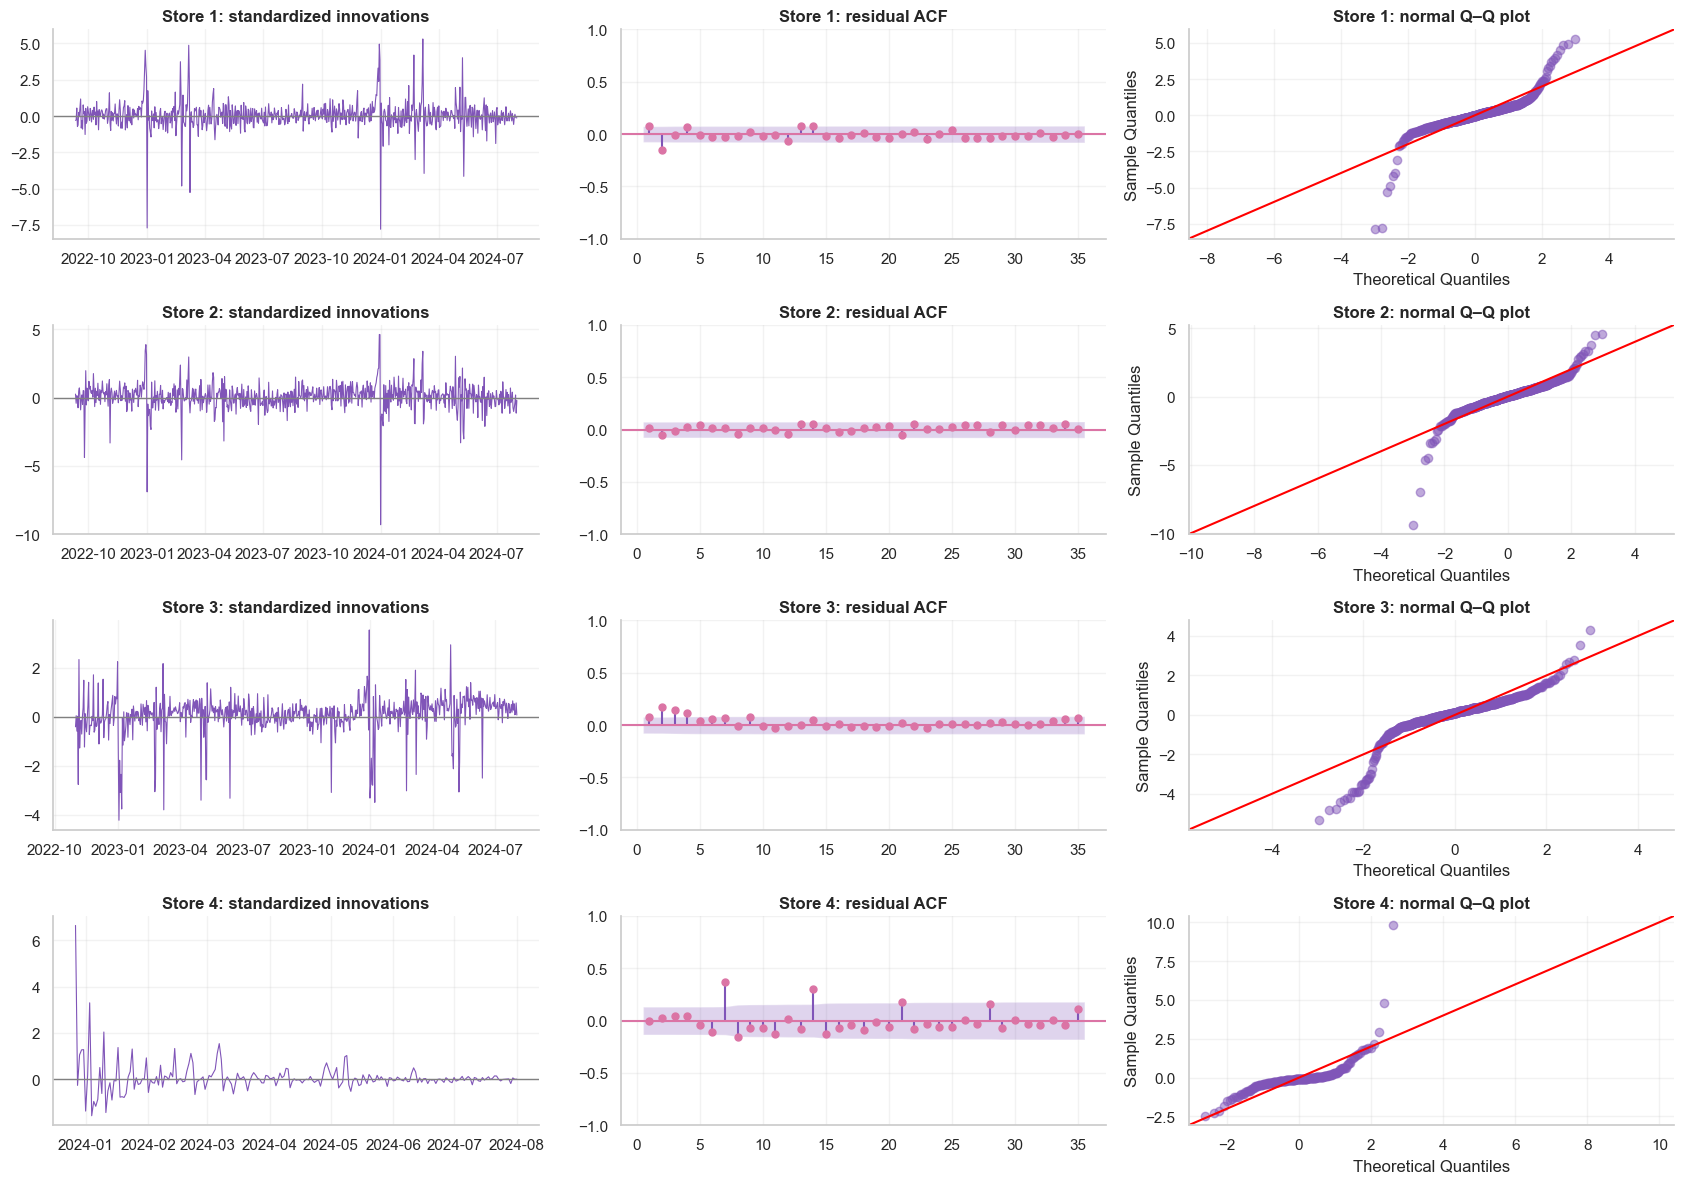

,store_id,diagnostic_start,diagnostic_end,n,mean_standardized_innovation,std_standardized_innovation
0,1,2022-09-11,2024-08-01,691,0.056,0.998
1,2,2022-09-11,2024-08-01,691,0.067,1.002
2,3,2022-10-31,2024-08-01,641,0.075,0.807
3,4,2023-12-27,2024-08-01,219,0.076,0.671


,store_id,lag,lb_stat,lb_pvalue
0,1,7,24.352,0.0001858
1,1,14,37.119,0.0002137
2,1,28,45.315,0.01087
3,2,7,3.853,0.5707
4,2,14,11.071,0.5228
5,2,28,20.404,0.772
6,3,7,52.078,5.199e-10
7,3,14,57.859,5.528e-08
8,3,28,59.750,0.0001812
9,4,7,34.160,2.213e-06


In [18]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.diagnostic import acorr_ljungbox

leading_arima_name = (
    complete_classical_summary.index[
        complete_classical_summary.index.isin(
            arima_scores["model"].unique()
        )
    ][0]
)

leading_spec = next(
    spec for spec in arima_candidates
    if spec["model"] == leading_arima_name
)

# AR and MA parameters, including seasonal ones.
model_df = (
    leading_spec["order"][0]
    + leading_spec["order"][2]
    + leading_spec["seasonal_order"][0]
    + leading_spec["seasonal_order"][2]
)

diagnostic_rows = []
ljung_box_parts = []

fig, axes = plt.subplots(
    len(store_series), 3,
    figsize=(17, 12),
    squeeze=False,
)

for row, store_id in enumerate(sorted(store_series)):
    fitted = arima_last_fold_fits[(leading_arima_name, store_id)]
    train = fold_data[(last_fold, store_id)]["train"]

    innovations = pd.Series(
        fitted.filter_results.standardized_forecasts_error[0],
        index=train.index,
        name="standardized_innovation",
    )

    start_position = max(
        int(getattr(fitted, "loglikelihood_burn", 0)),
        2 * SEASON_LENGTH,
    )

    # Do not include the imputed day's innovation in diagnostics.
    raw_train = store_series[store_id].reindex(train.index)
    missing_positions = np.flatnonzero(raw_train.isna().to_numpy())

    if len(missing_positions):
        start_position = max(
            start_position,
            int(missing_positions[-1]) + 1 + 2 * SEASON_LENGTH,
        )

    innovations = innovations.iloc[start_position:]

    if not np.isfinite(innovations.to_numpy()).all():
        raise ValueError("Non-finite diagnostic innovations.")

    diagnostic_rows.append({
        "store_id": store_id,
        "diagnostic_start": innovations.index.min(),
        "diagnostic_end": innovations.index.max(),
        "n": len(innovations),
        "mean_standardized_innovation": innovations.mean(),
        "std_standardized_innovation": innovations.std(),
    })

    lb = acorr_ljungbox(
        innovations,
        lags=[7, 14, 28],
        model_df=model_df,
        return_df=True,
    )
    lb.index.name = "lag"
    lb = lb.reset_index()
    lb.insert(0, "store_id", store_id)
    ljung_box_parts.append(lb)

    axes[row, 0].plot(
        innovations.index,
        innovations,
        color=COLORS["purple"],
        linewidth=0.8,
    )
    axes[row, 0].axhline(0, color="grey", linewidth=1)
    axes[row, 0].set_title(f"Store {store_id}: standardized innovations")

    plot_acf(
        innovations,
        lags=35,
        zero=False,
        ax=axes[row, 1],
        color=COLORS["pink"],
    )
    axes[row, 1].set_title(f"Store {store_id}: residual ACF")

    qqplot(
        innovations,
        fit=True,
        line="45",
        ax=axes[row, 2],
        markerfacecolor=COLORS["purple"],
        markeredgecolor=COLORS["purple"],
        alpha=0.5,
    )
    axes[row, 2].set_title(f"Store {store_id}: normal Q–Q plot")

plt.tight_layout()
plt.show()

innovation_summary = pd.DataFrame(diagnostic_rows)
ljung_box_results = pd.concat(ljung_box_parts, ignore_index=True)

display(innovation_summary)
display(
    ljung_box_results.style.format({
        "lb_stat": "{:.3f}",
        "lb_pvalue": "{:.4g}",
    })
)

ljung_box_results.to_csv(
    RESULTS_DIR / "leading_sarima_ljung_box.csv",
    index=False,
)

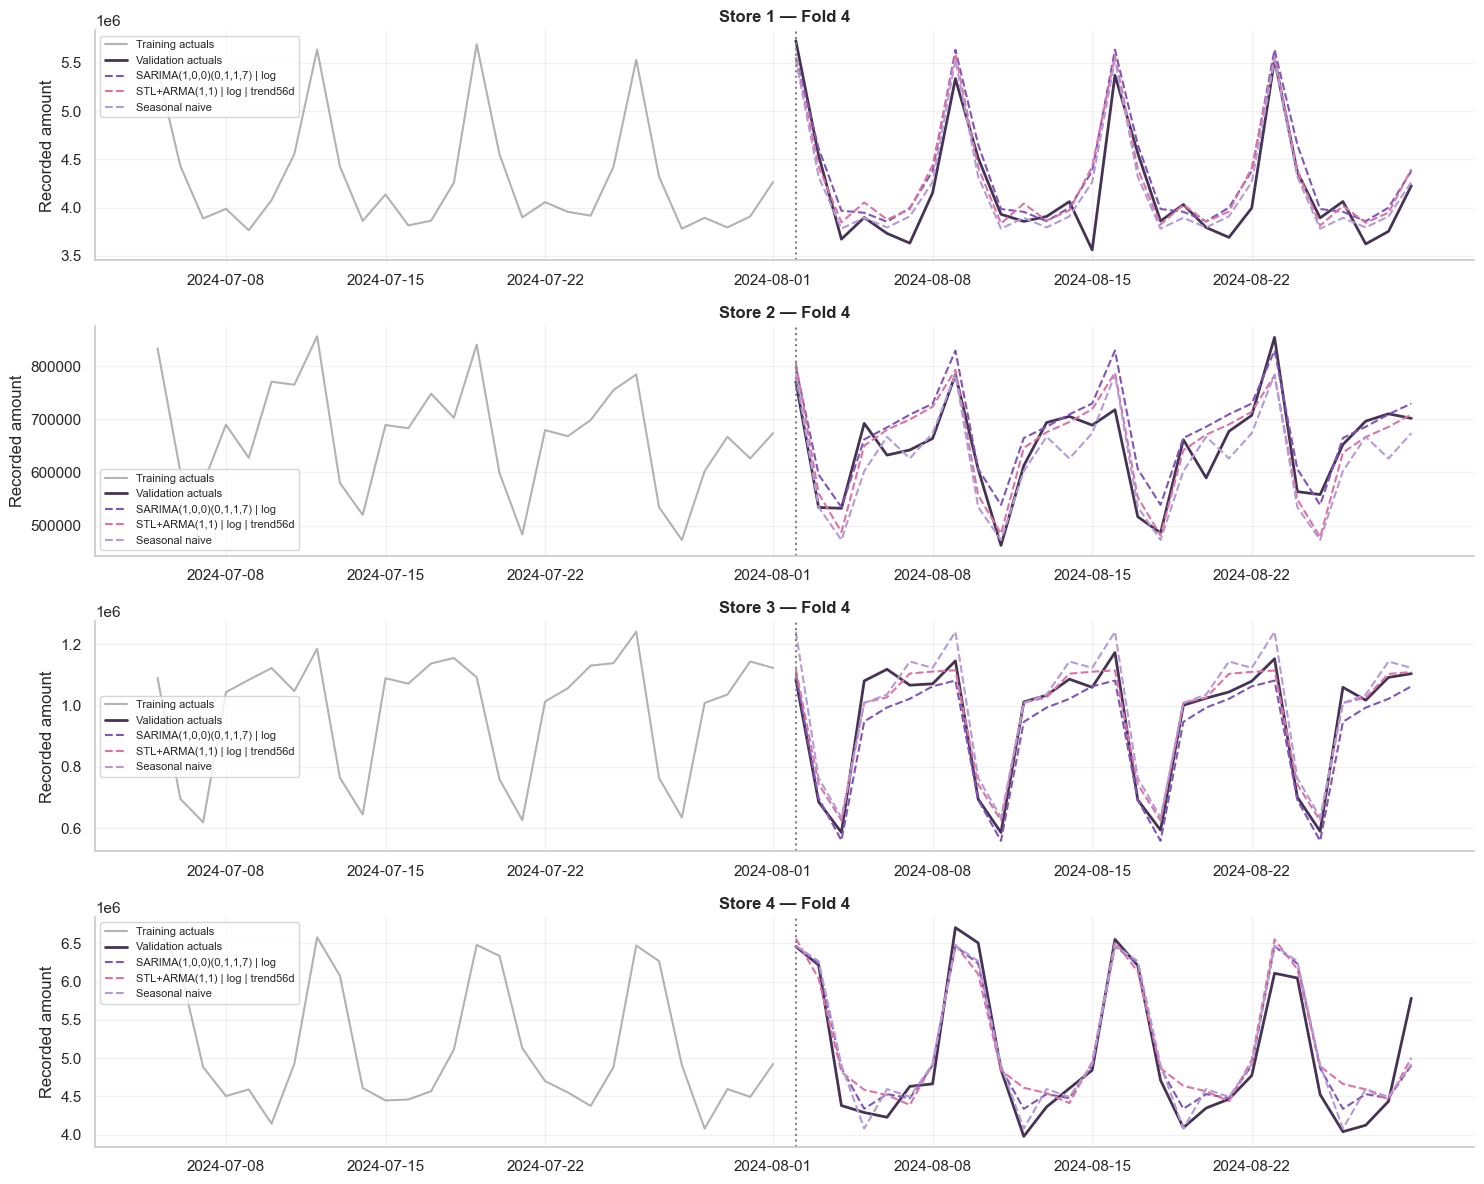

store_id,1,2,3,4
model,,,,
"SARIMA(1,0,0)(0,1,1,7) | log",6.670,6.465,13.489,5.561
"STL+ARMA(1,1) | log | trend56d",11.140,5.849,7.697,11.661
Seasonal naive,9.794,9.397,10.300,9.597


In [19]:
best_decomposition_name = (
    complete_classical_summary.index[
        complete_classical_summary.index.isin(
            decomposition_scores["model"].unique()
        )
    ][0]
)

selected_predictions = pd.concat([
    arima_predictions.loc[
        arima_predictions["model"].eq(leading_arima_name)
    ],
    decomposition_predictions.loc[
        decomposition_predictions["model"].eq(best_decomposition_name)
    ],
    baseline_predictions.loc[
        baseline_predictions["model"].eq("Seasonal naive")
    ],
], ignore_index=True)

plot_models = {
    leading_arima_name: COLORS["purple"],
    best_decomposition_name: COLORS["pink"],
    "Seasonal naive": COLORS["lavender"],
}

fig, axes = plt.subplots(
    len(store_series), 1,
    figsize=(15, 12),
)

for ax, store_id in zip(axes, sorted(store_series)):
    data = fold_data[(last_fold, store_id)]
    train = data["train"]
    valid = data["valid"]

    ax.plot(
        train.tail(28).index,
        train.tail(28),
        color="grey",
        alpha=0.6,
        label="Training actuals",
    )
    ax.plot(
        valid.index, valid,
        color=COLORS["dark"],
        linewidth=2,
        label="Validation actuals",
    )

    for model_name, color in plot_models.items():
        subset = selected_predictions.loc[
            selected_predictions["fold"].eq(last_fold)
            & selected_predictions["store_id"].eq(store_id)
            & selected_predictions["model"].eq(model_name)
        ].sort_values("date")

        ax.plot(
            subset["date"],
            subset["prediction"],
            color=color,
            linestyle="--",
            label=model_name,
        )

    ax.axvline(valid.index.min(), color="grey", linestyle=":")
    ax.set_title(f"Store {store_id} — Fold {last_fold}")
    ax.set_ylabel("Recorded amount")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

display(
    all_classical_scores.loc[
        all_classical_scores["model"].isin(plot_models)
    ]
    .groupby(["model", "store_id"])["WAPE_pct"]
    .mean()
    .unstack("store_id")
)

## 8. Conclusions and Limitations

### Forecasting performance

SARIMA(1,0,0)(0,1,1,7) on the log scale is the leading complete candidate,
with mean store–fold WAPE of 8.046%. Seasonal naive achieves 9.772%,
and the best decomposition pipeline achieves 9.087%.

The original-scale version of the leading SARIMA is close at 8.121%.
The small difference does not establish a decisive advantage for log
transformation.

Performance varies by store. Among the three inspected methods, SARIMA
has the lowest mean WAPE for stores 1 and 4, while the decomposition
pipeline performs better for stores 2 and 3.

### Residual diagnostics

Ljung–Box tests reject the absence of serial correlation at lags 7, 14,
and 28 for stores 1, 3, and 4. They do not reject it for store 2.
The leading model therefore leaves detectable temporal structure in
several stores.

These exploratory diagnostics use last-fold training innovations.
They do not replace multi-step validation errors or establish that
residuals are independent or normally distributed.

### Interpretation

Weekly structure is important: seasonal naive outperforms non-seasonal
baselines, and a weekly SARIMA improves on it further.

More complex smoothing does not automatically improve forecasting.
The best smoothing candidate remains behind seasonal naive on average.

The tested decomposition pipelines depend on how trend and seasonality
are extrapolated. Their results should not be generalized to every
possible decomposition-based method.

### Evaluation limitations

We used four expanding-window folds and generated complete 28-day
forecasts without validation updates. All reported rankings are
development-stage model-selection results.

Validation covers late spring and summer, providing limited evidence
about year-end peaks. Earlier EDA also informed candidate design,
so CV is not a fully independent assessment of the entire workflow.

The final holdout remains unopened. We will compare further forecasting
approaches before freezing the final selection.

### Next steps

We retain seasonal naive, both leading SARIMA scales, and the best
decomposition pipeline as reference candidates.

Further experiments will examine calendar/Fourier features, SARIMAX,
state-space models, Prophet, and ML/DL approaches using the same
forecast origins and horizon.

In [20]:
import platform
import statsmodels

prediction_columns = [
    "model", "fold", "store_id", "date", "actual", "prediction"
]

classical_predictions = pd.concat(
    [
        baseline_predictions[prediction_columns],
        smoothing_predictions[prediction_columns],
        arima_predictions[prediction_columns],
        decomposition_predictions[prediction_columns],
    ],
    ignore_index=True,
)

prediction_key = ["model", "fold", "store_id", "date"]

assert not classical_predictions.duplicated(prediction_key).any()
assert classical_predictions["date"].max() < TEST_START
assert np.isfinite(
    classical_predictions[["actual", "prediction"]].to_numpy()
).all()

# Verify equal targets across models for each validation observation.
actual_consistency = (
    classical_predictions
    .groupby(["fold", "store_id", "date"])["actual"]
    .nunique()
)
assert actual_consistency.eq(1).all()

# Every successfully scored model–store–fold must contain 28 forecasts.
prediction_counts = (
    classical_predictions
    .groupby(["model", "fold", "store_id"])
    .size()
)
assert prediction_counts.eq(HORIZON).all()
assert len(prediction_counts) == len(all_classical_scores)

classical_predictions["error"] = (
    classical_predictions["prediction"]
    - classical_predictions["actual"]
)
classical_predictions["absolute_error"] = (
    classical_predictions["error"].abs()
)

classical_predictions.to_csv(
    RESULTS_DIR / "classical_cv_predictions.csv",
    index=False,
    date_format="%Y-%m-%d",
)

all_classical_scores.to_csv(
    RESULTS_DIR / "classical_cv_scores.csv",
    index=False,
)

all_classical_summary.to_csv(
    RESULTS_DIR / "classical_cv_summary.csv"
)

reference_candidates = [
    "Seasonal naive",
    "SARIMA(1,0,0)(0,1,1,7) | log",
    "SARIMA(1,0,0)(0,1,1,7) | original",
    best_decomposition_name,
]

assert set(reference_candidates).issubset(
    complete_classical_summary.index
)

selection_record = {
    "status": "development comparison; final selection not frozen",
    "primary_metric": "mean WAPE across equally weighted store-folds",
    "forecast_horizon_days": HORIZON,
    "cv_folds": len(cv_schedule),
    "leading_candidate": complete_classical_summary.index[0],
    "reference_candidates": reference_candidates,
    "holdout_used": False,
    "versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "statsmodels": statsmodels.__version__,
    },
}

with (RESULTS_DIR / "classical_selection.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(selection_record, file, ensure_ascii=False, indent=2)

print("Classical CV results exported successfully.")
print(f"Forecast rows: {len(classical_predictions):,}")
print(f"Complete candidates: {len(complete_classical_summary)}")

Classical CV results exported successfully.
Forecast rows: 23,072
Complete candidates: 45
